# 00 · Dataset Overview — BSDS500

**Project:** SVD-based digital watermarking & steganography (course 01076020)

**What this notebook answers:** *What data do we have?* It describes the raw image files
**before any processing**: how many images, in which splits, what format and colour mode,
how big they are, and how the sizes are distributed.

**How to read it.** Every section has the same three parts:
1. a short note on *what is being measured and why*,
2. the code and its output (tables and charts),
3. a one-paragraph *takeaway* written from the actual numbers.

**What comes next.** `01_eda_pixels_svd.ipynb` looks inside the images (pixel values and singular values).

**Output file:** `results/dataset_stats.csv` — one row per image (split, file name, format, width, height, colour mode, file size).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.titleweight": "bold"})
BLUE, GRAY = "#2f6db5", "#6b7280"
pd.options.display.float_format = "{:,.1f}".format

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # this notebook lives in <repo>/notebooks/
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "images"
OUT_CSV = ROOT / "results" / "dataset_stats.csv"
SPLITS = ["train", "val", "test"]
print("Reading images from: data/images/{train,val,test}")

Reading images from: data/images/{train,val,test}


## 1. Read every image file

For each `.jpg` we record its **split** (train / val / test), **format**, **colour mode**
(RGB = colour, L = grayscale), **width × height in pixels**, and **file size in KB**.
Only the file header is read here; the pixel values are analysed in notebook 01.

In [2]:
rows = []
for split in SPLITS:
    for fp in sorted((DATA_DIR / split).glob("*.jpg")):
        with Image.open(fp) as im:
            fmt, mode, (w, h) = im.format, im.mode, im.size
        rows.append({"split": split, "filename": fp.name, "format": fmt, "mode": mode,
                     "width": w, "height": h, "size_kb": round(fp.stat().st_size / 1024, 1)})
df = pd.DataFrame(rows)
display(Markdown(f"**{len(df)} image files read.** First 5 rows of the table (one row = one image):"))
display(df.head(5))

**500 image files read.** First 5 rows of the table (one row = one image):

,split,filename,format,mode,width,height,size_kb
0,train,100075.jpg,JPEG,RGB,481,321,73.3
1,train,100080.jpg,JPEG,RGB,321,481,39.9
2,train,100098.jpg,JPEG,RGB,481,321,102.4
3,train,103041.jpg,JPEG,RGB,481,321,56.2
4,train,104022.jpg,JPEG,RGB,321,481,67.9


## 2. Dataset overview

*Why:* the report must state how many data items we have (the course requires **at least 150**)
and the share of each format.

In [3]:
n = len(df)
need = 150
overview = pd.DataFrame({
    "Value": [f"{n}",
              f"{'Yes' if n >= need else 'No'} (requirement: at least {need})",
              ", ".join(f"{k} {v} ({v/n*100:.1f}%)" for k, v in df["format"].value_counts().items()),
              ", ".join(f"{k} {v} ({v/n*100:.1f}%)" for k, v in df["mode"].value_counts().items())]},
    index=["Total number of images", "Meets the minimum-size requirement?", "File format", "Colour mode (RGB = colour)"])
display(overview)

split_tbl = df.groupby("split").size().reindex(SPLITS).to_frame("Images")
split_tbl["% of all images"] = split_tbl["Images"] / n * 100
split_tbl.index.name = "Split"
display(Markdown("**Images per split**"))
display(split_tbl)

,Value
Total number of images,500
Meets the minimum-size requirement?,Yes (requirement: at least 150)
File format,JPEG 500 (100.0%)
Colour mode (RGB = colour),RGB 500 (100.0%)


**Images per split**

,Images,% of all images
Split,,
train,200,40.0
val,100,20.0
test,200,40.0


## 3. Image sizes

*Why:* the method cuts each image into 8×8 blocks, so we need to know whether all images have the same
size and whether the sides are multiples of 8.

**How to read the table:** each row is one measurement; the columns summarise it over all images
(average, largest value found, smallest value found).

In [4]:
size_tbl = pd.DataFrame({
    "Average": [df["width"].mean(), df["height"].mean(), df["size_kb"].mean()],
    "Largest": [df["width"].max(), df["height"].max(), df["size_kb"].max()],
    "Smallest": [df["width"].min(), df["height"].min(), df["size_kb"].min()]},
    index=["Width (pixels)", "Height (pixels)", "File size (KB)"])
display(size_tbl)

dims = df.groupby(["width", "height"]).size().reset_index(name="Images")
dims["Orientation"] = np.where(dims["width"] > dims["height"], "landscape", np.where(dims["width"] < dims["height"], "portrait", "square"))
dims["% of images"] = dims["Images"] / n * 100
dims["Size (width × height)"] = dims["width"].astype(str) + " × " + dims["height"].astype(str)
dims = dims.sort_values("Images", ascending=False).set_index("Size (width × height)")[["Orientation", "Images", "% of images"]]
display(Markdown("**Distinct image sizes**"))
display(dims)
n_div8 = int(((df["width"] % 8 == 0) & (df["height"] % 8 == 0)).sum())
print(f"Images whose width AND height are both multiples of 8: {n_div8} of {n}")

,Average,Largest,Smallest
Width (pixels),432.4,481.0,321.0
Height (pixels),369.6,481.0,321.0
File size (KB),72.2,123.1,23.1


**Distinct image sizes**

,Orientation,Images,% of images
Size (width × height),,,
481 × 321,landscape,348,69.6
321 × 481,portrait,152,30.4


Images whose width AND height are both multiples of 8: 0 of 500


## 4. Charts

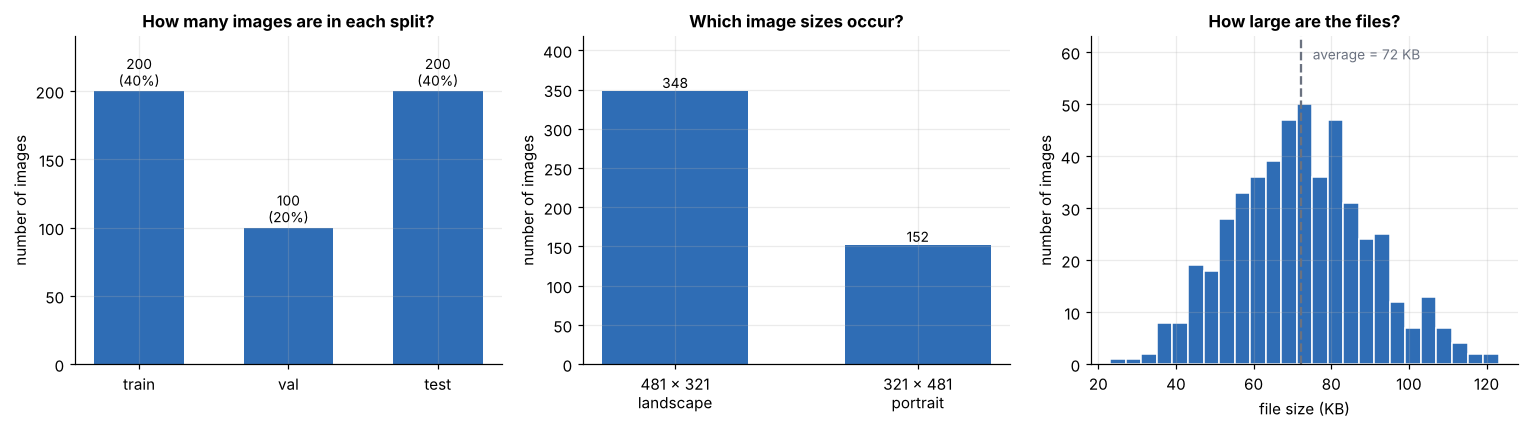

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# (a) images per split
bars = ax[0].bar(split_tbl.index, split_tbl["Images"], color=BLUE, width=0.6)
for b, v, p in zip(bars, split_tbl["Images"], split_tbl["% of all images"]):
    ax[0].text(b.get_x() + b.get_width()/2, v + 4, f"{v}\n({p:.0f}%)", ha="center", fontsize=9)
ax[0].set_title("How many images are in each split?"); ax[0].set_ylabel("number of images")
ax[0].set_ylim(0, split_tbl["Images"].max() * 1.2)

# (b) distinct sizes
lbl = [f"{i}\n{o}" for i, o in zip(dims.index, dims["Orientation"])]
bars = ax[1].bar(lbl, dims["Images"], color=BLUE, width=0.6)
for b, v in zip(bars, dims["Images"]):
    ax[1].text(b.get_x() + b.get_width()/2, v + 4, str(v), ha="center", fontsize=9)
ax[1].set_title("Which image sizes occur?"); ax[1].set_ylabel("number of images")
ax[1].set_ylim(0, dims["Images"].max() * 1.2)

# (c) file size
ax[2].hist(df["size_kb"], bins=25, color=BLUE, edgecolor="white")
ax[2].set_ylim(0, ax[2].get_ylim()[1] * 1.2)
ax[2].axvline(df["size_kb"].mean(), color=GRAY, ls="--", lw=1.5)
ax[2].text(df["size_kb"].mean() + 3, ax[2].get_ylim()[1] * 0.93, f"average = {df['size_kb'].mean():.0f} KB", color=GRAY, fontsize=9)
ax[2].set_title("How large are the files?"); ax[2].set_xlabel("file size (KB)"); ax[2].set_ylabel("number of images")
plt.tight_layout(); plt.show()

## 5. Takeaway

In [6]:
d = dims.iloc[0]
display(Markdown(f"""
* **Enough data:** {n} images, well above the required 150. They come split {split_tbl.loc['train','Images']} / {split_tbl.loc['val','Images']} / {split_tbl.loc['test','Images']} (train / val / test).
* **One format, one colour mode:** {', '.join(df['format'].unique())} files, colour mode {', '.join(df['mode'].unique())}. Colour images must be converted to grayscale before SVD, because SVD works on a single matrix of numbers.
* **Sizes are nearly uniform:** only {len(dims)} distinct sizes ({', '.join(dims.index)}), i.e. the same picture shape in landscape and portrait.
* **Block-size problem:** {n - n_div8} of {n} images do not have sides divisible by 8, so every image must be cropped slightly before it can be cut into 8×8 blocks. That is handled in notebook 01.
"""))


* **Enough data:** 500 images, well above the required 150. They come split 200 / 100 / 200 (train / val / test).
* **One format, one colour mode:** JPEG files, colour mode RGB. Colour images must be converted to grayscale before SVD, because SVD works on a single matrix of numbers.
* **Sizes are nearly uniform:** only 2 distinct sizes (481 × 321, 321 × 481), i.e. the same picture shape in landscape and portrait.
* **Block-size problem:** 500 of 500 images do not have sides divisible by 8, so every image must be cropped slightly before it can be cut into 8×8 blocks. That is handled in notebook 01.


## 6. Save the per-image table

The table is written to `results/dataset_stats.csv` so that later notebooks and the report can reuse it.

In [7]:
OUT_CSV.parent.mkdir(exist_ok=True)
df.to_csv(OUT_CSV, index=False)
print(f"Saved {len(df)} rows -> results/{OUT_CSV.name}")

Saved 500 rows -> results/dataset_stats.csv
